# What transfers to a new molecule? Readable KAN equations and an interpolation ledger

The dataset notebooks in this series found the same pattern again and again: a model that
scores well when test reactions reuse molecules it was trained on can fail on a molecule it
has never seen. This notebook makes that systematic, and asks how much of each model, and of
each descriptor, survives the step from interpolation to extrapolation.

**Readable equations from a KAN.** A KAN with no hidden layer, `layers=(d, 1)`, is a sum of
one curve per descriptor. Each curve is matched to the simplest form in a small library that
reproduces it (a line, 1/x, log, exponential, quadratic, V, step or window), with one support
rule: an edge needs at least three distinct descriptor values on each side, otherwise it is a
lookup of a few molecules rather than a shape. Each matched form becomes a *piece*, a unit shape
of one descriptor in its own units: 0 below a threshold and 1 above, 1 inside a window, a
standardized line, a squared distance from an optimum. The equation is a sum of the pieces that
earn their place under cross-validation. Where the residual holds structure, PySR (if installed:
`pip install "pycse[pysr]"`) is given the chosen pieces and only `+`, `-` and `*`, and proposes
products, which is where one factor changes the effect of another. PySR never sees a raw
descriptor, so every variable in its equation is a named, plotted shape.

**The ledger.** Every model is scored twice, on the same folds throughout:

- *random folds*: test reactions reuse molecules seen in training (interpolation);
- *new molecules*: whole molecules are held out (extrapolation).

The models form a ladder, from the training mean through the sum of pieces, the pieces chosen
by how well they predict held-out molecules, PySR products, the additive KAN the pieces came
from, the usual one-hidden-layer KAN, and gradient boosting. For each rung the ledger gives the
gain on each scheme. A gain that appears only on random folds is the model learning the
molecules it was trained on. The same accounting is done per descriptor (drop its pieces from
the sum, refit, see what is lost on each scheme), and per held-out molecule, whose error is set
against its distance to the nearest training molecule in the space of that molecule's own
descriptors.

**The memorized share** is the random-fold score lost when pieces must help held-out molecules
to be chosen: what the equation knew only because it had seen the molecules.

The first section is a synthetic calibration with a known answer, including an interaction.
The five datasets follow, each loaded exactly as in its own notebook. All of them download their
data at run time.

In [1]:
import os

os.environ["JAX_PLATFORM_NAME"] = "cpu"
import time
import warnings

warnings.filterwarnings("ignore")

import importlib.metadata as md
import importlib.util

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.ensemble import GradientBoostingClassifier, GradientBoostingRegressor

from pycse.sklearn._plotstyle import BASELINE, MUTED, PX, SERIES, finish_axes, style_axes
from pycse.sklearn.kan import KAN
from pycse.sklearn.kan_interpret import prune_collinear
from pycse.sklearn.kan_symbolic import PieceModel, transfer_ledger

HAS_PYSR = importlib.util.find_spec("pysr") is not None
versions = {p: md.version(p) for p in ["pycse", "jax", "numpy", "scikit-learn", "scipy"]}
if HAS_PYSR:
    versions["pysr"] = md.version("pysr")
print("Versions: " + ", ".join(f"{k} {v}" for k, v in versions.items()))
print("PySR products:", "on" if HAS_PYSR else 'off (pip install "pycse[pysr]" to turn them on)')

Versions: pycse 2.13.0, jax 0.12.0.1, numpy 2.5.4, scikit-learn 1.9.1, scipy 1.18.1, pysr 2.7.2
PySR products: on


## Helpers

In [2]:
LEDGERS, EQUATIONS = {}, {}
SHOW = ["pieces, chosen on new molecules", "KAN", "Gradient Boosting"]


def upper_rungs(n_rows, n_features, task):
    # The usual KAN of the dataset notebooks, and gradient boosting, as the top of the ladder.
    wide = n_rows >= 1000
    kan = KAN(layers=(n_features, 8 if wide else 4, 1), grid_size=5 if wide else 3,
              l1_spline=1e-3, entropy_reg=1e-3)  # fmt: skip
    gb = (GradientBoostingRegressor if task == "regression" else GradientBoostingClassifier)(
        n_estimators=300, learning_rate=0.1, max_depth=4, min_samples_split=5,
        min_samples_leaf=3, subsample=0.8, random_state=42,
    )  # fmt: skip
    return {"KAN": kan, "Gradient Boosting": gb}


def plot_ledger(L, title):
    fig, axes = plt.subplots(1, 2, figsize=(12, 3.8), gridspec_kw={"width_ratios": [1.3, 1]})
    ax = axes[0]
    style_axes(ax)
    lad = L.ladder.drop(index="mean")
    pos = np.arange(len(lad))
    floor = -1.0 if L.metric == "R2" else 0.4
    for off, col, c, lab in [(-0.19, "random folds", MUTED, "random folds"),
                             (0.19, "new molecules", SERIES[0], f"new {L.group_name}s")]:  # fmt: skip
        v = lad[col].to_numpy()
        ax.barh(pos + off, np.maximum(v, floor), height=0.36, color=c, linewidth=0, label=lab)
        for p, val in zip(pos, v):
            if val < floor:
                ax.text(floor, p + off, f" {val:.1f}", va="center", fontsize=7)
    ax.axvline(L.ladder.loc["mean", "new molecules"] if L.metric == "R2" else 0.5,
               color=BASELINE, linewidth=PX, linestyle="--")  # fmt: skip
    ax.set_yticks(pos)
    ax.set_yticklabels(lad.index, fontsize=8)
    ax.invert_yaxis()
    ax.set_xlim(floor, 1.0)
    ax.legend(frameon=False, fontsize=8, loc="lower right")
    finish_axes(ax, f"{title}: the ladder", L.metric, "")
    ax = axes[1]
    style_axes(ax)
    for k, r in enumerate(SHOW):
        ax.plot([0, 1, 2], L.tiers.loc[r, ["near", "middle", "far"]], marker="o",
                color=SERIES[k], linewidth=1.5, label=r)  # fmt: skip
    ax.plot([0, 1, 2], L.tiers.loc["mean", ["near", "middle", "far"]], color=BASELINE,
            linewidth=PX, linestyle="--", label="mean")  # fmt: skip
    ax.set_xticks([0, 1, 2])
    ax.set_xticklabels(["nearest third", "middle third", "farthest third"], fontsize=8)
    ax.legend(frameon=False, fontsize=8)
    unit = "P(active)" if L.metric == "AUC" else "target units"
    finish_axes(ax, f"Error on held-out {L.group_name}s by distance to training", "",
                f"mean |error| ({unit})")  # fmt: skip
    plt.tight_layout()
    plt.show()


def run_dataset(tag, X_df, y, groups, task, group_name, *, hypothesis=(), per_feature=None,
                prune=True):  # fmt: skip
    names = list(X_df.columns)
    X = X_df.to_numpy(dtype=float)
    if prune:
        kept, dropped = prune_collinear(X, names, 0.85, keep_first=list(hypothesis))
        for n, (partner, r) in dropped.items():
            print(f"pruned {n}: |r| = {r:.2f} with {partner}")
        names, X = kept, X_df[kept].to_numpy(dtype=float)
    y, groups = np.asarray(y, dtype=float), np.asarray(groups)
    print(f"{tag}: {len(X)} reactions, {len(names)} descriptors, {len(np.unique(groups))} {group_name}s, {task}")
    t0 = time.time()
    L = transfer_ledger(
        X, y, groups, names, task=task, group_name=group_name,
        models=upper_rungs(len(X), len(names), task), fit_kwargs={"KAN": {"maxiter": 300}},
        piece_options={"per_feature": per_feature}, products=HAS_PYSR, verbose=False,
    )  # fmt: skip
    print(f"({time.time() - t0:.0f} s)\n")
    print(L)
    plot_ledger(L, tag)
    eqs = {}
    for how in ["random", "groups"]:
        pm = PieceModel(feature_names=names, per_feature=per_feature, select_on=how,
                        products=HAS_PYSR).fit(X, y, groups=groups)  # fmt: skip
        eqs[how] = pm
        label = "random folds" if how == "random" else f"new {group_name}s"
        print(f"\nEquation on all {len(X)} reactions, pieces chosen on {label}:")
        print(pm.equation())
    LEDGERS[tag], EQUATIONS[tag] = L, eqs
    return L

## 1. Calibration: a known equation with an interaction

Six hundred reactions generated from textbook terms, as in `KAN_Known_Truth_Benchmark`, except
that the Hammett slope changes across the ligation cliff: rho = +2.0 for ligands below 32 %
buried volume and -0.5 above it, a change of mechanism with the ligation state.

log10 k = -3 + (2.0 - 2.5 S) sigma - 1.5 S - 15/(2.303 R) (1/T - 1/298.15) - 0.01 (dE + 15)^2,
with S = 1 / (1 + exp(-(%Vbur - 32))), plus an unrelated descriptor and noise of 0.15.

What the pipeline should do: find a step at 32 %, a 1/T term whose coefficient gives 15 kcal/mol,
a volcano at -15 and a Hammett line; drop the unrelated descriptor; and, with PySR on, find the
product of the Hammett piece with the step. Nothing can be memorized here, so every rung should
keep its score on new substituents.

Calibration: 600 reactions, 5 descriptors, 12 substituents, regression


(259 s)

Ladder (R2; random folds reuse substituents seen in training, new = whole substituents held out):
                                 random folds  new molecules  gain, random  gain, new  kept on new
rung                                                                                              
mean                                   -0.025         -0.020           NaN        NaN        0.826
pieces                                  0.859          0.870         0.884      0.891        1.013
pieces, chosen on new molecules         0.859          0.870         0.000      0.000        1.013
pieces + products                       0.978          0.967         0.119      0.097        0.989
KAN additive                            0.847          0.858        -0.131     -0.109        1.013
KAN                                     0.983          0.976         0.136      0.118        0.994
Gradient Boosting                       0.962          0.947        -0.021     -0.030        0.984

R

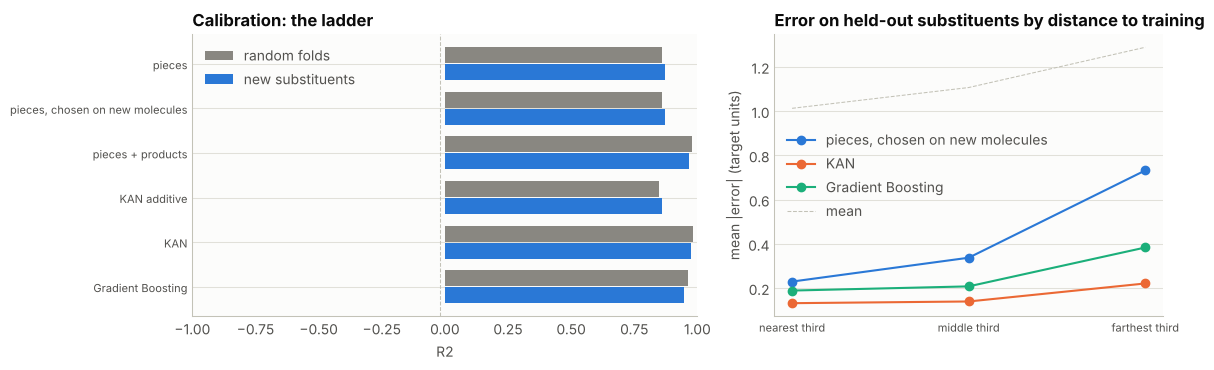


Equation on all 600 reactions, pieces chosen on random folds:
pieces:
  p0 = S((pct_Vbur_min - 31.9) / 1.61)   [0 below 31.9, 1 above]
  p1 = 328 / T_K
  p2 = ((dE_bind + 14.9) / 8.63)^2   [turns at -14.9]
  p3 = (sigma_p - 0.131) / 0.423
y = 8.199 -1.97*p0 -9.825*p1 -0.7473*p2 +0.1927*p3
    + p3*(0.6258306 - p0)
  where S(t) = 1 / (1 + exp(-t)), a step from 0 to 1 of width about 4 in t



Equation on all 600 reactions, pieces chosen on new substituents:
pieces:
  p0 = S((pct_Vbur_min - 31.9) / 1.61)   [0 below 31.9, 1 above]
  p1 = 328 / T_K
  p2 = ((dE_bind + 14.9) / 8.63)^2   [turns at -14.9]
  p3 = (sigma_p - 0.131) / 0.423
y = 8.199 -1.97*p0 -9.825*p1 -0.7473*p2 +0.1927*p3
    + p3*(0.6258304 - p0)
  where S(t) = 1 / (1 + exp(-t)), a step from 0 to 1 of width about 4 in t

Barrier from the 1/T piece: 14.75 kcal/mol (generated: 15.0)


In [3]:
R_CAL = 1.987e-3
SIGMA_P = {"NO2": 0.78, "CN": 0.66, "CF3": 0.54, "CO2Me": 0.45, "Cl": 0.23, "Br": 0.23,
           "F": 0.06, "H": 0.00, "Me": -0.17, "tBu": -0.20, "OMe": -0.27, "NMe2": -0.83}  # fmt: skip
rng = np.random.default_rng(2021)
N = 600
subst = rng.choice(list(SIGMA_P), size=N)
cal = pd.DataFrame({
    "sigma_p": [SIGMA_P[s] for s in subst], "T_K": rng.uniform(288.0, 368.0, N),
    "pct_Vbur_min": rng.uniform(22.0, 50.0, N), "dE_bind": rng.uniform(-30.0, 0.0, N),
    "noise_descriptor": rng.normal(size=N),
})  # fmt: skip
S_cliff = 1.0 / (1.0 + np.exp(-(cal.pct_Vbur_min - 32.0)))
y_cal = (-3.0 + (2.0 - 2.5 * S_cliff) * cal.sigma_p - 1.5 * S_cliff
         - 15.0 / (2.303 * R_CAL) * (1.0 / cal.T_K - 1.0 / 298.15)
         - 0.01 * (cal.dE_bind + 15.0) ** 2 + rng.normal(0, 0.15, N))  # fmt: skip
L = run_dataset("Calibration", cal, y_cal, subst, "regression", "substituent",
                per_feature={"T_K": ["inverse"]}, prune=False)  # fmt: skip
pm = EQUATIONS["Calibration"]["groups"]
for k, j in enumerate(pm.chosen_):
    if pm.pieces_[j].form == "inverse":  # the piece is mean(T) / T
        a = pm.linear_.coef_[k] * pm.pieces_[j].mean
        print(f"\nBarrier from the 1/T piece: {-a * 2.303 * R_CAL:.2f} kcal/mol (generated: 15.0)")

## 2. Known-truth benchmark (additive)

The synthetic data of `KAN_Known_Truth_Benchmark`: the same terms with no interaction. The equation should come back term by term, and everything should transfer.

In [4]:
R_CAL = 1.987e-3  # kcal/(mol K)
SIGMA_P = {
    "NO2": 0.78, "CN": 0.66, "CF3": 0.54, "CO2Me": 0.45, "Cl": 0.23, "Br": 0.23,
    "F": 0.06, "H": 0.00, "Me": -0.17, "tBu": -0.20, "OMe": -0.27, "NMe2": -0.83,
}  # fmt: skip
RHO, DH_ACT, CLIFF_DROP, CLIFF_W, VOLCANO_A, E_OPT = 1.5, 15.0, 1.5, 1.0, 0.01, -15.0
LOG_K0, NOISE_SD, N = -3.0, 0.15, 600


def term_hammett(s):
    return RHO * s


def term_eyring(T):
    return -DH_ACT / (2.303 * R_CAL) * (1.0 / T - 1.0 / 298.15)


def term_cliff(v):
    return -CLIFF_DROP / (1.0 + np.exp(-(v - 32.0) / CLIFF_W))


def term_volcano(e):
    return -VOLCANO_A * (e - E_OPT) ** 2


def term_none(z):
    return np.zeros_like(np.asarray(z, dtype=float))


TRUTH = {
    "sigma_p": term_hammett,
    "T_K": term_eyring,
    "pct_Vbur_min": term_cliff,
    "dE_bind": term_volcano,
    "noise_descriptor": term_none,
}

rng = np.random.default_rng(2021)
subst = rng.choice(list(SIGMA_P), size=N)
df = pd.DataFrame(
    {
        "substituent": subst,
        "sigma_p": [SIGMA_P[s] for s in subst],
        "T_K": rng.uniform(288.0, 368.0, N),
        "pct_Vbur_min": rng.uniform(22.0, 50.0, N),
        "dE_bind": rng.uniform(-30.0, 0.0, N),
        "noise_descriptor": rng.normal(size=N),
    }
)
df["log10_k"] = LOG_K0 + sum(TRUTH[f](df[f].to_numpy()) for f in TRUTH) + rng.normal(0, NOISE_SD, N)

X_df = df[list(TRUTH)]
y = df["log10_k"].to_numpy()
TASK = "regression"
Y_LABEL = "log10 k"
COMPONENT = {"sigma_p": "substrate", "T_K": "conditions", "pct_Vbur_min": "ligand", "dE_bind": "catalyst", "noise_descriptor": "none"}
SUCCESS = (y > np.median(y)).astype(int)
SUCCESS_RULE = "log10 k above the median"
_ = (df.head())
GROUPS = df["substituent"].to_numpy()

Known-truth benchmark (additive): 600 reactions, 5 descriptors, 12 substituents, regression


(156 s)

Ladder (R2; random folds reuse substituents seen in training, new = whole substituents held out):
                                 random folds  new molecules  gain, random  gain, new  kept on new
rung                                                                                              
mean                                   -0.017         -0.040           NaN        NaN        2.369
pieces                                  0.985          0.966         1.002      1.006        0.981
pieces, chosen on new molecules         0.985          0.966         0.000     -0.000        0.981
pieces + products                       0.985          0.966         0.000      0.000        0.981
KAN additive                            0.980          0.966        -0.005     -0.000        0.986
KAN                                     0.983          0.967         0.004      0.001        0.983
Gradient Boosting                       0.964          0.938        -0.019     -0.029        0.973

R

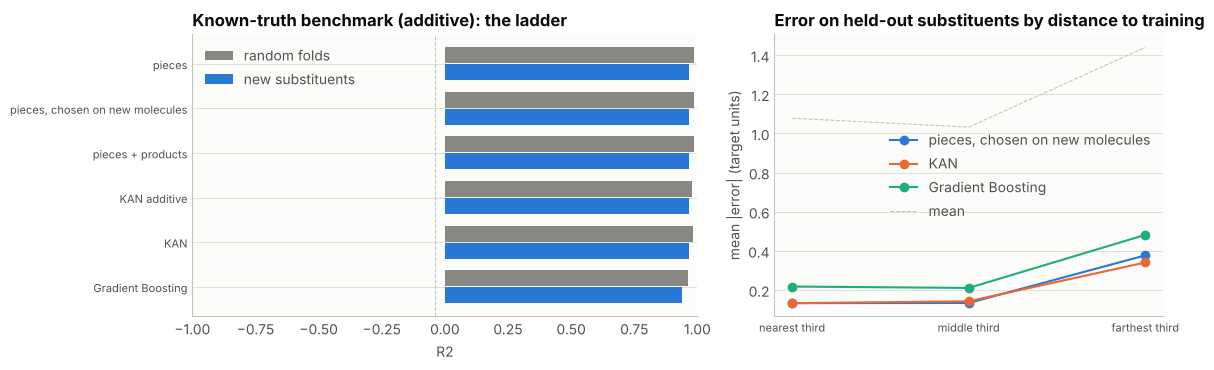


Equation on all 600 reactions, pieces chosen on random folds:
pieces:
  p0 = S((pct_Vbur_min - 31.7) / 1.64)   [0 below 31.7, 1 above]
  p1 = 328 / T_K
  p2 = ((dE_bind + 15) / 8.63)^2   [turns at -15]
  p3 = (sigma_p - 0.131) / 0.423
y = 8.364 -1.612*p0 -10.08*p1 -0.7494*p2 +0.6413*p3
  where S(t) = 1 / (1 + exp(-t)), a step from 0 to 1 of width about 4 in t



Equation on all 600 reactions, pieces chosen on new substituents:
pieces:
  p0 = S((pct_Vbur_min - 31.7) / 1.64)   [0 below 31.7, 1 above]
  p1 = 328 / T_K
  p2 = ((dE_bind + 15) / 8.63)^2   [turns at -15]
  p3 = (sigma_p - 0.131) / 0.423
y = 8.364 -1.612*p0 -10.08*p1 -0.7494*p2 +0.6413*p3
  where S(t) = 1 / (1 + exp(-t)), a step from 0 to 1 of width about 4 in t


In [5]:
L = run_dataset('Known-truth benchmark (additive)', X_df, y, GROUPS, TASK, 'substituent',
                hypothesis=['sigma_p', 'T_K', 'pct_Vbur_min', 'dE_bind'], per_feature={"T_K": ["inverse"]})

## 3. Phosphine ligation-state cliff

Newman-Stonebraker et al., Science 2021: 450 Ni-catalysed couplings over 90 phosphines, active or not. Held out: whole ligands.

In [6]:
from rdkit import Chem, RDLogger

RDLogger.DisableLog("rdApp.*")  # the kraken table has blank SMILES rows

BASE = "https://raw.githubusercontent.com/doyle-lab-ucla/ochem-data/main/"
rxn = pd.read_csv(BASE + "Vbur/rxns/smiles.csv")
kraken = pd.read_csv(BASE + "kraken/kraken.csv")
SPHERE = 4.0 / 3.0 * np.pi * 3.5**3  # 179.6 cubic angstrom


def canon(s):
    m = Chem.MolFromSmiles(str(s))
    return Chem.MolToSmiles(m) if m is not None else None


kraken["key"] = kraken["ligand"].astype(str).str.lower().str.strip()
kraken["csmi"] = kraken["can_smiles"].where(kraken["can_smiles"].notna()).map(canon)
kraken = kraken.drop_duplicates("key")
rxn["key"] = rxn["ligand_name"].str.lower().str.strip()
rxn["csmi"] = rxn["ligand_smiles"].map(canon)

by_name = rxn.merge(kraken, on="key", how="left", suffixes=("", "_k"))
missing = by_name["id"].isna()
by_smi = rxn[missing].merge(kraken.drop_duplicates("csmi"), on="csmi", how="left", suffixes=("", "_k"))
data = pd.concat([by_name[~missing], by_smi]).reset_index(drop=True)
print(f"{len(rxn)} reactions; matched by name {(~missing).sum()}, by SMILES {by_smi['id'].notna().sum()}, unmatched {data['id'].isna().sum()}")
data = data[data["id"].notna()].copy()

KRAKEN = {
    "pct_Vbur_min": ("vbur_vbur_min", 100.0 / SPHERE),
    "pct_Vbur_Boltz": ("vbur_vbur_boltz", 100.0 / SPHERE),
    "pct_Vbur_max": ("vbur_vbur_max", 100.0 / SPHERE),
    "Sterimol_B1": ("sterimol_B1_boltz", 1.0),
    "Sterimol_B5": ("sterimol_B5_boltz", 1.0),
    "Sterimol_L": ("sterimol_L_boltz", 1.0),
    "E_HOMO": ("fmo_e_homo_boltz", 1.0),
    "E_LUMO": ("fmo_e_lumo_boltz", 1.0),
    "V_min": ("vmin_vmin_boltz", 1.0),
    "NBO_charge_P": ("nbo_P_boltz", 1.0),
    "pyramidalization_P": ("pyr_P_boltz", 1.0),
    "dipole": ("dipolemoment_boltz", 1.0),
}
X_df = pd.DataFrame({k: data[c].astype(float) * s for k, (c, s) in KRAKEN.items()})

# the five substrate pairs, by SMILES
ELEC = {"ClC1=CC=C(C(F)(F)F)C=C1": "4-CF3-C6H4Cl", "ClC1=CC=C(OC)C=C1": "4-MeO-C6H4Cl"}
NUC = {
    "OB(O)C1=CC=C(C(F)(F)F)C=C1": "4-CF3-phenyl", "OB(O)C1=C(C)C=C(C)C=C1C": "mesityl",
    "OB(O)C1=CC=C(C(OCC)=O)C=C1": "4-CO2Et-phenyl", "OB(O)C1=CC=C(OC)C=C1": "4-MeO-phenyl",
    "OB(O)C1=CC=CC=C1": "phenyl",
}  # fmt: skip
data["reaction"] = data.chloride_smiles.map(ELEC) + " + " + data.boronic_acid_smiles.map(NUC) + "B(OH)2"
assert data["reaction"].notna().all() and data["reaction"].nunique() == 5
REACTIONS = sorted(data["reaction"].unique())
for r in REACTIONS[1:]:  # the first pair is the reference level
    X_df["rxn: " + r] = (data["reaction"] == r).astype(float)
X_df.index = data.index

# Active, relative to the reaction. The five pairs differ in intrinsic reactivity: the best
# ligand reaches 91 % with one pair and 25 % with another, so one pooled yield cut would call
# most ligands active in the easy pair and almost none in the hard one. The paper shades an
# inactive band per reaction; here a ligand counts as active when it reaches a quarter of the
# best yield obtained with that same substrate pair.
best = data.groupby("reaction")["yield"].transform("max")
ACTIVE_FRACTION = 0.25
y = (data["yield"] >= ACTIVE_FRACTION * best).astype(int).to_numpy()
TASK = "classification"
Y_LABEL = "P(active)"
SUCCESS = y
SUCCESS_RULE = f"yield at least {ACTIVE_FRACTION:.0%} of the best yield with the same substrate pair"
COMPONENT = {k: "ligand sterics" for k in ["pct_Vbur_min", "pct_Vbur_Boltz", "pct_Vbur_max", "Sterimol_B1", "Sterimol_B5", "Sterimol_L"]}
COMPONENT.update({k: "ligand electronics" for k in ["E_HOMO", "E_LUMO", "V_min", "NBO_charge_P", "pyramidalization_P", "dipole"]})
COMPONENT.update({c: "substrate pair" for c in X_df.columns if c.startswith("rxn:")})
print(data.groupby("reaction").agg(mean_yield=("yield", "mean"), best=("yield", "max"), n=("yield", "size"), active=("yield", lambda s: (s >= ACTIVE_FRACTION * s.max()).mean())).round(2))
_ = (X_df.describe().T[["mean", "min", "max"]].round(2))
GROUPS = data["key"].to_numpy()

450 reactions; matched by name 450, by SMILES 0, unmatched 0
                                     mean_yield   best   n  active
reaction                                                          
4-CF3-C6H4Cl + 4-MeO-phenylB(OH)2         36.97   91.0  90    0.57
4-MeO-C6H4Cl + 4-CF3-phenylB(OH)2         20.14   90.0  90    0.33
4-MeO-C6H4Cl + 4-CO2Et-phenylB(OH)2        9.56  100.0  90    0.13
4-MeO-C6H4Cl + mesitylB(OH)2               9.73   63.0  90    0.24
4-MeO-C6H4Cl + phenylB(OH)2               15.16  100.0  90    0.23


pruned pct_Vbur_max: |r| = 0.87 with pct_Vbur_Boltz
Phosphine ligation-state cliff: 450 reactions, 15 descriptors, 90 ligands, classification


(377 s)

Ladder (AUC; random folds reuse ligands seen in training, new = whole ligands held out):
                                 random folds  new molecules  gain, random  gain, new  kept on new
rung                                                                                              
mean                                    0.500          0.500           NaN        NaN        1.000
pieces                                  0.912          0.887         0.412      0.387        0.972
pieces, chosen on new molecules         0.932          0.874         0.019     -0.013        0.938
pieces + products                       0.908          0.891        -0.024      0.017        0.981
KAN additive                            0.930          0.781         0.022     -0.110        0.839
KAN                                     0.873          0.779        -0.057     -0.002        0.892
Gradient Boosting                       0.938          0.920         0.065      0.141        0.981

Random-fol

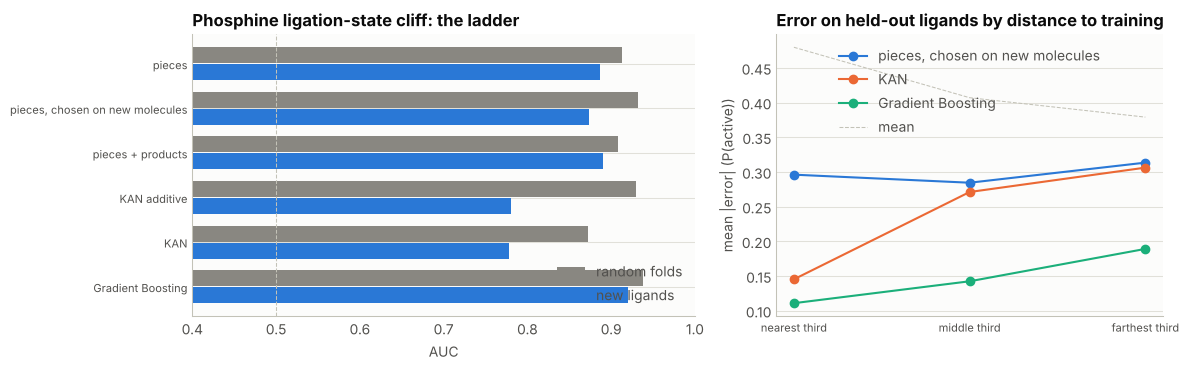


Equation on all 450 reactions, pieces chosen on random folds:
pieces:
  p0 = W(E_LUMO; -0.04, -0.0142, 0.00342)   [1 inside -0.04 to -0.0142]
  p1 = |pct_Vbur_Boltz - 26.6| / 12
  p2 = S((V_min + 0.0488) / 0.0021)   [0 below -0.0488, 1 above]
  p3 = [rxn: 4-MeO-C6H4Cl + 4-CO2Et-phenylB(OH)2 = 1]  (0 or 1)
  p4 = |pyramidalization_P - 0.933| / 0.0368
  p5 = [rxn: 4-MeO-C6H4Cl + phenylB(OH)2 = 1]  (0 or 1)
  p6 = [rxn: 4-MeO-C6H4Cl + mesitylB(OH)2 = 1]  (0 or 1)
  p7 = [rxn: 4-MeO-C6H4Cl + 4-CF3-phenylB(OH)2 = 1]  (0 or 1)
  p8 = (dipole - 1.89) / 1.11
  p9 = (pyramidalization_P - 0.918) / 0.0368
y = 0.726 +0.379*p0 -0.1882*p1 -0.5193*p2 -0.4333*p3 -0.02302*p4 -0.3333*p5 -0.3222*p6 -0.2333*p7 +0.07597*p8 +0.0841*p9
    + p0*p2*(p1*(-p8 - 1*1.3316336 + 0.07203129) + p9)
  where S(t) = 1 / (1 + exp(-t)), a step from 0 to 1 of width about 4 in t; W(x; a, b, w) = S((x - a) / w) - S((x - b) / w), 1 between a and b



Equation on all 450 reactions, pieces chosen on new ligands:
pieces:
  p0 = W(E_LUMO; -0.04, -0.0142, 0.00342)   [1 inside -0.04 to -0.0142]
  p1 = |pct_Vbur_Boltz - 26.6| / 12
  p2 = S((V_min + 0.0488) / 0.0021)   [0 below -0.0488, 1 above]
  p3 = [rxn: 4-MeO-C6H4Cl + 4-CO2Et-phenylB(OH)2 = 1]  (0 or 1)
  p4 = (pyramidalization_P - 0.918) / 0.0368
  p5 = (dipole - 1.89) / 1.11
  p6 = [rxn: 4-MeO-C6H4Cl + phenylB(OH)2 = 1]  (0 or 1)
  p7 = [rxn: 4-MeO-C6H4Cl + mesitylB(OH)2 = 1]  (0 or 1)
  p8 = [rxn: 4-MeO-C6H4Cl + 4-CF3-phenylB(OH)2 = 1]  (0 or 1)
y = 0.7084 +0.3875*p0 -0.1903*p1 -0.5208*p2 -0.4333*p3 +0.09902*p4 +0.08068*p5 -0.3333*p6 -0.3222*p7 -0.2333*p8
    + (p1 - 1*1.4749954)*0.021278875*p5*p5
  where S(t) = 1 / (1 + exp(-t)), a step from 0 to 1 of width about 4 in t; W(x; a, b, w) = S((x - a) / w) - S((x - b) / w), 1 between a and b


In [7]:
L = run_dataset('Phosphine ligation-state cliff', X_df, y, GROUPS, TASK, 'ligand',
                hypothesis=['pct_Vbur_min'], per_feature=None)

## 4. Buchwald-Hartwig amination, DFT descriptors

Ahneman et al., Science 2018: 3955 reactions. Held out: whole isoxazole additives; aryl halides, bases and ligands are still seen in training, so a descriptor of those components can transfer across additives without saying anything about new aryl halides.

In [8]:
URL = "https://raw.githubusercontent.com/b-shields/edbo/master/examples/DOE/data/aryl_amination/science_dft.csv"
RXN = "https://raw.githubusercontent.com/doylelab/rxnpredict/master/"
raw = pd.read_csv(URL)
CHOSEN = {
    "additive": [
        "additive_E_LUMO", "additive_E_HOMO", "additive_.C3_NMR_shift", "additive_.C4_NMR_shift",
        "additive_.C5_NMR_shift", "additive_.N1_electrostatic_charge", "additive_.O1_electrostatic_charge",
        "additive_dipole_moment", "additive_molecular_volume",
    ],
    "aryl halide": [
        "aryl_halide_E_LUMO", "aryl_halide_E_HOMO", "aryl_halide_.C1_NMR_shift",
        "aryl_halide_.C1_electrostatic_charge", "aryl_halide_.C4_NMR_shift", "aryl_halide_.H2_NMR_shift",
        "aryl_halide_dipole_moment", "aryl_halide_molecular_volume", "aryl_halide_hardness",
    ],
    "base": ["base_E_HOMO", "base_.N1_electrostatic_charge", "base_molecular_volume"],
    "ligand": ["ligand_.P1_electrostatic_charge", "ligand_dipole_moment", "ligand_.C1_NMR_shift"],
}  # fmt: skip
COMPONENT = {c: comp for comp, cols in CHOSEN.items() for c in cols}
X_df = raw[list(COMPONENT)].copy()
const = [c for c in X_df.columns if X_df[c].nunique() <= 1]
X_df = X_df.drop(columns=const)
print(f"Dropped constant descriptors: {const}")
y = raw["yield"].to_numpy(dtype=float)
TASK = "regression"
Y_LABEL = "yield (%)"
SUCCESS = (y > 20.0).astype(int)
SUCCESS_RULE = "yield above 20 %"

stats = X_df.agg(["mean", "std"]).T
print(f"Descriptor means are {stats['mean'].abs().max():.3f} or less and standard deviations "
      f"{stats['std'].min():.3f} to {stats['std'].max():.3f}: the table is standardized.")  # fmt: skip


def recover_names(key_col, table_col, table, names, checks):
    """Map each dataset level of key_col to a molecule name, then verify on other descriptors."""
    rank = np.argsort(np.argsort(table[table_col].to_numpy()))
    levels = np.sort(raw[key_col].unique())
    assert len(levels) == len(table), f"{len(levels)} levels vs {len(table)} molecules"
    mapping = {i: levels[rank[i]] for i in range(len(table))}
    for s_col, t_col in checks:
        lv, rk = np.sort(raw[s_col].unique()), np.argsort(np.argsort(table[t_col].to_numpy()))
        for i in range(len(table)):
            seen = raw.loc[raw[key_col] == mapping[i], s_col].unique()
            assert len(seen) == 1 and np.isclose(seen[0], lv[rk[i]]), f"{t_col} disagrees for {names[i]}"
    return {mapping[i]: names[i] for i in range(len(table))}


def name_list(stem):
    n = pd.read_csv(RXN + f"smiles/{stem}-list.csv")
    return n["name"].tolist()[: len(pd.read_csv(RXN + f"R/{stem}.csv"))]



tables = {s: pd.read_csv(RXN + f"R/{s}.csv") for s in ["aryl_halide", "additive", "base", "ligand"]}
raw["aryl_halide"] = raw["aryl_halide_.C1_NMR_shift"].map(
    recover_names("aryl_halide_.C1_NMR_shift", "aryl_halide_*C1_NMR_shift", tables["aryl_halide"], name_list("aryl_halide"),
                  [("aryl_halide_.C4_NMR_shift", "aryl_halide_*C4_NMR_shift"), ("aryl_halide_E_LUMO", "aryl_halide_E_LUMO"),
                   ("aryl_halide_molecular_volume", "aryl_halide_molecular_volume")])
)  # fmt: skip
raw["additive"] = raw["additive_.C3_NMR_shift"].map(
    recover_names("additive_.C3_NMR_shift", "additive_*C3_NMR_shift", tables["additive"], name_list("additive"),
                  [("additive_.C4_NMR_shift", "additive_*C4_NMR_shift"), ("additive_E_LUMO", "additive_E_LUMO")])
)  # fmt: skip
raw["base"] = raw["base_E_HOMO"].map(
    recover_names("base_E_HOMO", "base_E_HOMO", tables["base"], name_list("base"),
                  [("base_molecular_volume", "base_molecular_volume"), ("base_.N1_electrostatic_charge", "base_*N1_electrostatic_charge")])
)  # fmt: skip
raw["ligand"] = raw["ligand_dipole_moment"].map(
    recover_names("ligand_dipole_moment", "ligand_dipole_moment", tables["ligand"], name_list("ligand"),
                  [("ligand_.C1_NMR_shift", "ligand_*C1_NMR_shift"), ("ligand_.P1_electrostatic_charge", "ligand_*P1_electrostatic_charge")])
)  # fmt: skip
raw["halide"] = np.select([raw.aryl_halide.str.contains("iodo"), raw.aryl_halide.str.contains("bromo")], ["I", "Br"], "Cl")

# The scaffold is the aryl halide without its halogen, keeping where the halogen was:
# 2- and 3-halopyridines are different substrates even though both lose a halogen to
# give pyridine. The names are written inconsistently ("1-ethyl-4-iodobenzene" but
# "1-bromo-4-ethylbenzene"), so the scaffold is read from the substituent named.


def scaffold_of(name):
    if "pyridine" in name:
        return f"pyridin-{name[0]}-yl"
    for key, label in [("trifluoromethyl", "4-(trifluoromethyl)phenyl"), ("methoxy", "4-methoxyphenyl"), ("ethyl", "4-ethylphenyl")]:
        if key in name:
            return label
    raise ValueError(name)


raw["scaffold"] = raw.aryl_halide.map(scaffold_of)
assert raw["scaffold"].nunique() == 5
print("Names recovered and verified against two further descriptors each.")
print(f"{len(raw)} reactions: {raw.aryl_halide.nunique()} aryl halides, {raw.additive.nunique()} additives, "
      f"{raw.base.nunique()} bases ({', '.join(sorted(raw.base.unique()))}), {raw.ligand.nunique()} ligands "
      f"({', '.join(sorted(raw.ligand.unique()))}).")  # fmt: skip
GROUPS = raw["additive"].to_numpy()

Dropped constant descriptors: []
Descriptor means are 0.025 or less and standard deviations 0.994 to 1.005: the table is standardized.


Names recovered and verified against two further descriptors each.
3955 reactions: 15 aryl halides, 22 additives, 3 bases (BTMG, MTBD, P2Et), 4 ligands (AdBrettPhos, XPhos, t-BuBrettPhos, t-BuXPhos).


pruned aryl_halide_E_HOMO: |r| = 0.99 with aryl_halide_E_LUMO
pruned aryl_halide_hardness: |r| = 0.99 with aryl_halide_E_LUMO
pruned ligand_.C1_NMR_shift: |r| = 0.88 with ligand_dipole_moment
Buchwald-Hartwig amination, DFT descriptors: 3955 reactions, 21 descriptors, 22 additives, regression


(580 s)

Ladder (R2; random folds reuse additives seen in training, new = whole additives held out):
                                 random folds  new molecules  gain, random  gain, new  kept on new
rung                                                                                              
mean                                   -0.001         -0.044           NaN        NaN       36.279
pieces                                  0.523          0.374         0.524      0.418        0.716
pieces, chosen on new molecules         0.506          0.380        -0.017      0.006        0.751
pieces + products                       0.543          0.397         0.037      0.016        0.730
KAN additive                            0.697          0.517         0.153      0.120        0.742
KAN                                     0.890          0.369         0.193     -0.148        0.415
Gradient Boosting                       0.911          0.627         0.021      0.257        0.688

Random-

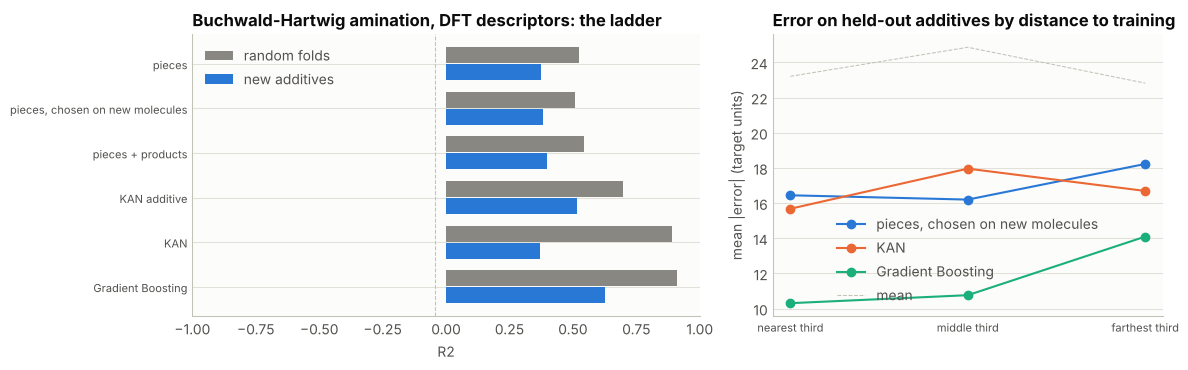


Equation on all 3955 reactions, pieces chosen on random folds:
pieces:
  p0 = |aryl_halide_molecular_volume - 0.547| / 1
  p1 = (aryl_halide_.H2_NMR_shift + 0.000123) / 1
  p2 = S((additive_.C3_NMR_shift + 0.393) / 0.178)   [0 below -0.393, 1 above]
  p3 = (ligand_.P1_electrostatic_charge - 0.000956) / 1
  p4 = (base_.N1_electrostatic_charge + 3.12e-05) / 1
  p5 = ((aryl_halide_dipole_moment + 0.607) / 1)^2   [turns at -0.607]
  p6 = (additive_.O1_electrostatic_charge - 0.00818) / 1
  p7 = |additive_.O1_electrostatic_charge - 0.877| / 1
  p8 = (aryl_halide_molecular_volume + 0.00063) / 1
  p9 = (aryl_halide_.C1_electrostatic_charge - 0.000278) / 1
  p10 = (aryl_halide_.C1_NMR_shift + 0.000319) / 1
  p11 = S((aryl_halide_.C4_NMR_shift - 0.225) / 0.186)   [0 below 0.225, 1 above]
y = -21.53 +52.64*p0 +1.216*p1 +13.23*p2 -5.744*p3 +5.609*p4 +12.41*p5 -8.831*p6 -7.517*p7 +38.35*p8 -11.33*p9 -8.708*p10 -34.42*p11
    + p10*(p8 + p8 - p9)
  where S(t) = 1 / (1 + exp(-t)), a step from 0 to 1


Equation on all 3955 reactions, pieces chosen on new additives:
pieces:
  p0 = |aryl_halide_molecular_volume - 0.547| / 1
  p1 = (aryl_halide_.H2_NMR_shift + 0.000123) / 1
  p2 = W(additive_.C4_NMR_shift; -2.15, -0.768, 0.375)   [1 inside -2.15 to -0.768]
  p3 = (base_.N1_electrostatic_charge + 3.12e-05) / 1
  p4 = (ligand_.P1_electrostatic_charge - 0.000956) / 1
  p5 = ((aryl_halide_dipole_moment + 0.607) / 1)^2   [turns at -0.607]
  p6 = (aryl_halide_molecular_volume + 0.00063) / 1
  p7 = (aryl_halide_.C1_electrostatic_charge - 0.000278) / 1
  p8 = (aryl_halide_.C1_NMR_shift + 0.000319) / 1
  p9 = S((aryl_halide_.C4_NMR_shift - 0.225) / 0.186)   [0 below 0.225, 1 above]
  p10 = S((aryl_halide_E_LUMO - 0.398) / 0.388)   [0 below 0.398, 1 above]
  p11 = |aryl_halide_.C1_NMR_shift + 0.684| / 1
y = -24 +64.41*p0 +13.96*p1 +27.34*p2 +5.603*p3 -5.505*p4 +10.03*p5 +49.55*p6 -8.272*p7 -7.267*p8 -68.26*p9 -37.25*p10 +11.81*p11
    + p4*(p4*p4*(-9.203263) - 1*(-9.203263))
  where S(t) = 1 / (

In [9]:
L = run_dataset('Buchwald-Hartwig amination, DFT descriptors', X_df, y, GROUPS, TASK, 'additive',
                hypothesis=[], per_feature=None)

## 5. Direct arylation with reaction conditions

Shields et al., Nature 2021: 1728 reactions, a full factorial over 12 ligands. Held out: whole ligands.

In [10]:
BASE = "https://raw.githubusercontent.com/b-shields/edbo/master/examples/DOE/data/direct_arylation/"
idx = pd.read_csv(BASE + "experiment_index.csv")
lig = pd.read_csv(BASE + "ligand-boltzmann_dft.csv")
bas = pd.read_csv(BASE + "base_dft.csv")
sol = pd.read_csv(BASE + "solvent_dft.csv")

LIG = {
    "ligand_pct_Vbur_P": "ligand_atom1_%VBur_Boltz", "ligand_E_HOMO": "ligand_homo_energy_Boltz",
    "ligand_E_LUMO": "ligand_lumo_energy_Boltz", "ligand_hardness": "ligand_hardness_Boltz",
    "ligand_dipole": "ligand_dipole_Boltz", "ligand_molar_volume": "ligand_molar_volume_Boltz",
}  # fmt: skip
BAS = {"base_dipole": "base_dipole", "base_molar_volume": "base_molar_volume", "base_E_HOMO": "base_homo_energy", "base_E_LUMO": "base_lumo_energy"}
SOL = {"solvent_dipole": "solvent_dipole", "solvent_molar_volume": "solvent_molar_volume", "solvent_E_HOMO": "solvent_homo_energy", "solvent_E_LUMO": "solvent_lumo_energy"}

df = idx.merge(lig[["ligand_SMILES", "ligand_file_name", *LIG.values()]].rename(columns={"ligand_SMILES": "Ligand_SMILES"}), on="Ligand_SMILES", how="left")
df = df.merge(bas[["base_SMILES", "base_file_name", *BAS.values()]].rename(columns={"base_SMILES": "Base_SMILES"}), on="Base_SMILES", how="left")
df = df.merge(sol[["solvent_SMILES", "solvent_file_name", *SOL.values()]].rename(columns={"solvent_SMILES": "Solvent_SMILES"}), on="Solvent_SMILES", how="left")
assert df[list(LIG.values())].notna().all().all() and len(df) == len(idx)
df["ligand_pct_Vbur_P"] = 100.0 * df["ligand_atom1_%VBur_Boltz"]  # fraction to percent

X_df = pd.DataFrame({"temperature_C": df["Temp_C"].astype(float), "concentration_M": df["Concentration"].astype(float)})
for new, old in {**LIG, **BAS, **SOL}.items():
    if new != "ligand_pct_Vbur_P":
        X_df[new] = df[old].astype(float)
    else:
        X_df[new] = df[new]
COMPONENT = {"temperature_C": "conditions", "concentration_M": "conditions"}
COMPONENT.update({k: "ligand" for k in LIG})
COMPONENT.update({k: "base" for k in BAS})
COMPONENT.update({k: "solvent" for k in SOL})
y = df["yield"].to_numpy(dtype=float)
TASK = "regression"
Y_LABEL = "yield (%)"
SUCCESS = (y > 20.0).astype(int)
SUCCESS_RULE = "yield above 20 %"
print(f"{len(df)} reactions: {df.ligand_file_name.nunique()} ligands x {df.base_file_name.nunique()} bases x {df.solvent_file_name.nunique()} solvents x {df.Concentration.nunique()} concentrations x {df.Temp_C.nunique()} temperatures")
for comp in ["ligand_file_name", "base_file_name", "solvent_file_name", "Temp_C", "Concentration"]:
    print(df.groupby(comp)["yield"].mean().round(1).sort_values(ascending=False).to_dict())
GROUPS = df["ligand_file_name"].to_numpy()

1728 reactions: 12 ligands x 4 bases x 4 solvents x 3 concentrations x 3 temperatures
{'X-Phos': 52.8, 'CgMe-PPh': 50.2, 'P(fur)3': 27.3, 'BrettPhos': 25.6, 'GorlosPhos': 19.2, 'JackiePhos': 17.7, 'PPh3': 16.6, 'tBPh-CPhos': 16.5, 'PCy3': 3.8, 'PPh2Me': 2.0, 'PPhtBu2': 0.4, 'PPhMe2': 0.3}
{'CsOAc': 22.8, 'KOPiv': 21.5, 'CsOPiv': 17.2, 'KOAc': 16.0}
{'DMAc': 30.4, 'BuCN': 20.6, 'p-Xylene': 13.5, 'BuOAc': 13.0}
{120: 24.1, 105: 20.3, 90: 13.7}
{0.153: 20.5, 0.1: 19.6, 0.057: 18.1}


pruned ligand_hardness: |r| = 0.87 with ligand_E_LUMO
pruned base_E_HOMO: |r| = 0.90 with base_dipole
pruned base_E_LUMO: |r| = 1.00 with base_dipole
pruned solvent_E_LUMO: |r| = 0.99 with solvent_dipole
Direct arylation with reaction conditions: 1728 reactions, 12 descriptors, 12 ligands, regression


(321 s)

Ladder (R2; random folds reuse ligands seen in training, new = whole ligands held out):
                                 random folds  new molecules  gain, random  gain, new  kept on new
rung                                                                                              
mean                                   -0.002         -0.435           NaN        NaN      217.784
pieces                                  0.538         -2.753         0.540     -2.318       -5.116
pieces, chosen on new molecules         0.084         -0.364        -0.454      2.389       -4.328
pieces + products                       0.557         -2.645         0.473     -2.282       -4.747
KAN additive                            0.589         -7.091         0.031     -4.446      -12.045
KAN                                     0.863         -3.970         0.274      3.121       -4.602
Gradient Boosting                       0.889         -1.752         0.026      2.218       -1.972

Random-fold

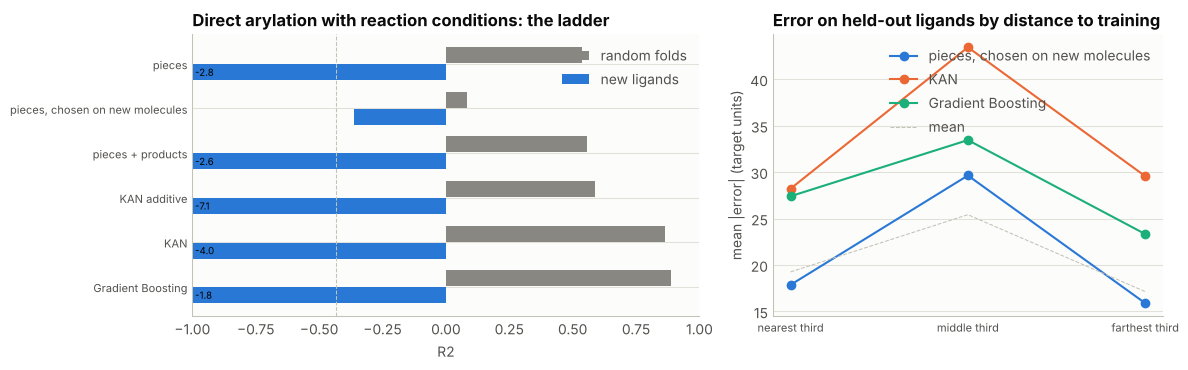


Equation on all 1728 reactions, pieces chosen on random folds:
pieces:
  p0 = (ligand_molar_volume - 3.11e+03) / 1.32e+03
  p1 = (ligand_dipole - 1.93) / 1.35
  p2 = W(ligand_E_HOMO; -0.223, -0.21, 0.00207)   [1 inside -0.223 to -0.21]
  p3 = |ligand_dipole - 2.39| / 1.35
  p4 = (solvent_molar_volume - 1.04e+03) / 201
  p5 = (temperature_C - 105) / 12.2
  p6 = ((solvent_dipole - 5.03) / 1.62)^2   [turns at 5.03]
  p7 = (solvent_E_HOMO + 0.261) / 0.0366
  p8 = |ligand_molar_volume - 2.41e+03| / 1.32e+03
  p9 = |ligand_pct_Vbur_P - 76.7| / 7.43
  p10 = ((ligand_E_LUMO + 0.435) / 0.0225)^2   [turns at -0.435]
  p11 = (ligand_pct_Vbur_P - 76.5) / 7.43
y = 24.78 +1.752*p0 -25.87*p1 +16.21*p2 -71.64*p3 -3.056*p4 +4.221*p5 -1.692*p6 +4.1*p7 +69.33*p8 -73.73*p9 +0.1905*p10 -17.25*p11
    + p9*(-2.9433475)*p7*p1
  where W(x; a, b, w) = S((x - a) / w) - S((x - b) / w), 1 between a and b



Equation on all 1728 reactions, pieces chosen on new ligands:
pieces:
  p0 = (solvent_molar_volume - 1.04e+03) / 201
  p1 = (temperature_C - 105) / 12.2
  p2 = ((solvent_dipole - 5.03) / 1.62)^2   [turns at 5.03]
y = 22.91 -4.07*p0 +4.221*p1 -0.9502*p2
    + p1*(-2.201592)*p0


In [11]:
L = run_dataset('Direct arylation with reaction conditions', X_df, y, GROUPS, TASK, 'ligand',
                hypothesis=[], per_feature=None)

## 6. Alcohol deoxyfluorination

Nielsen et al., JACS 2018: 740 reactions over 37 alcohols. Held out: whole alcohols.

In [12]:
URL = "https://raw.githubusercontent.com/doyle-lab-ucla/ochem-data/main/deoxyF/rxns/dft_from_paper/all.csv"
raw = pd.read_csv(URL)
X_df = raw.drop(columns=["index", "yield"]).copy()
const = [c for c in X_df.columns if X_df[c].nunique() <= 1]
X_df = X_df.drop(columns=const)
print(f"Dropped constant descriptors: {const}")
COMPONENT = {c: ("alcohol" if c.startswith("alcohol") else "base" if c.startswith("base") else "sulfonyl fluoride") for c in X_df.columns}
y = raw["yield"].to_numpy(dtype=float)
TASK = "regression"
Y_LABEL = "yield (%)"
SUCCESS = (y > 40.0).astype(int)
SUCCESS_RULE = "yield above 40 %"
n_alc = raw[[c for c in raw.columns if c.startswith("alcohol")]].drop_duplicates().shape[0]
print(f"{len(raw)} reactions: {n_alc} alcohols x {raw['base_.N1_exposed_area'].nunique()} bases x {raw['sulfonyl_fluoride_.S1_electrostatic_charge'].nunique()} sulfonyl fluorides")
cls = np.select([raw.alcohol_primary == 1, raw.alcohol_secondary == 1, raw.alcohol_tertiary == 1], ["primary", "secondary", "tertiary"], "other")
print(pd.DataFrame({"class": cls, "yield": y}).groupby("class")["yield"].agg(["mean", "count"]).round(1))
GROUPS = raw[[c for c in raw.columns if c.startswith("alcohol")]].round(6).astype(str).agg("|".join, axis=1).to_numpy()

Dropped constant descriptors: []
740 reactions: 37 alcohols x 4 bases x 4 sulfonyl fluorides
           mean  count
class                 
primary    49.7    320
secondary  36.5    380
tertiary    3.3     40


pruned alcohol_primary: |r| = 0.90 with alcohol_.C1_exposed_area
pruned sulfonyl_fluoride_.O1_electrostatic_charge: |r| = 0.90 with sulfonyl_fluoride_.F1_electrostatic_charge
Alcohol deoxyfluorination: 740 reactions, 21 descriptors, 37 alcohols, regression


(300 s)

Ladder (R2; random folds reuse alcohols seen in training, new = whole alcohols held out):
                                 random folds  new molecules  gain, random  gain, new  kept on new
rung                                                                                              
mean                                   -0.013         -0.251           NaN        NaN       19.890
pieces                                  0.451         -0.171         0.464      0.081       -0.378
pieces, chosen on new molecules         0.344         -0.050        -0.107      0.121       -0.145
pieces + products                       0.484         -0.145         0.140     -0.096       -0.301
KAN additive                            0.645         -3.401         0.161     -3.255       -5.272
KAN                                     0.862         -2.077         0.217      1.323       -2.411
Gradient Boosting                       0.929         -0.237         0.068      1.840       -0.255

Random-fo

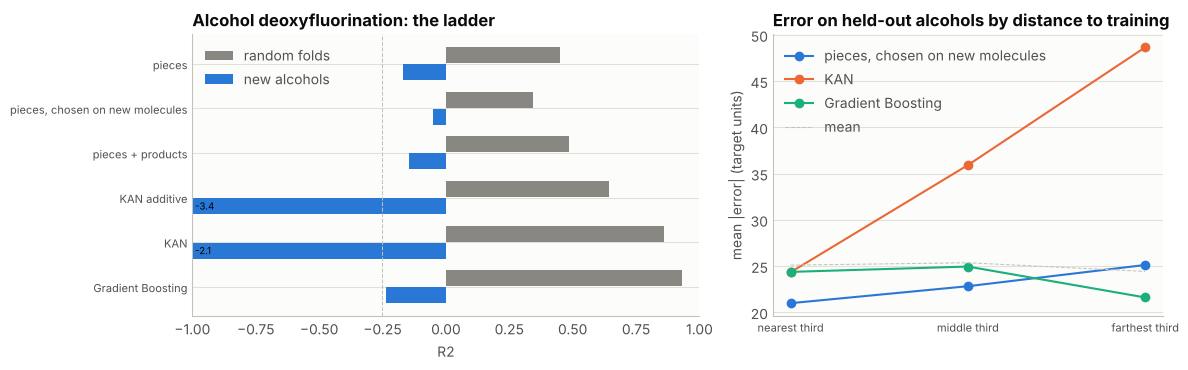


Equation on all 740 reactions, pieces chosen on random folds:
pieces:
  p0 = (alcohol_.C1_exposed_area - 9.23) / 4.04
  p1 = [alcohol_6.membered_ring = 1]  (0 or 1)
  p2 = [alcohol_secondary = 1]  (0 or 1)
  p3 = [alcohol_cyclic = 1]  (0 or 1)
  p4 = (sulfonyl_fluoride_.F1_electrostatic_charge + 0.196) / 0.0177
  p5 = [alcohol_allylic = 1]  (0 or 1)
  p6 = [alcohol_beta_carbonyl = 1]  (0 or 1)
  p7 = (base_.N1_exposed_area - 5.87) / 1
  p8 = [alcohol_5.membered_ring = 1]  (0 or 1)
  p9 = |alcohol_.C1_exposed_area - 4.81| / 4.04
  p10 = (alcohol_.C1_electrostatic_charge - 0.23) / 0.227
  p11 = [alcohol_7.membered_ring = 1]  (0 or 1)
y = -34.15 -11.99*p0 +0.4092*p1 +72.74*p2 -50.91*p3 +5.405*p4 -21.53*p5 -18.24*p6 -5.253*p7 +23.49*p8 +42.84*p9 -8.398*p10 +24.46*p11
    + p4*((p3 + p8)*8.6015215 - 1*4.184795)



Equation on all 740 reactions, pieces chosen on new alcohols:
pieces:
  p0 = (alcohol_.C1_electrostatic_charge - 0.23) / 0.227
  p1 = [alcohol_6.membered_ring = 1]  (0 or 1)
  p2 = [alcohol_secondary = 1]  (0 or 1)
  p3 = (sulfonyl_fluoride_.F1_electrostatic_charge + 0.196) / 0.0177
  p4 = (base_.N1_exposed_area - 5.87) / 1
  p5 = (sulfonyl_fluoride_.S1_electrostatic_charge - 0.94) / 0.0492
y = 38 -11.76*p0 -26.38*p1 +11.64*p2 +6.337*p3 -5.253*p4 +2.744*p5
    + p0*p4*(5.3263927 - p0)


In [13]:
L = run_dataset('Alcohol deoxyfluorination', X_df, y, GROUPS, TASK, 'alcohol',
                hypothesis=[], per_feature=None)

## 7. Across the datasets

One row per dataset: each rung's score on random folds and on new molecules, the memorized share
of the random-fold score, how much faster the error grows with distance for each rung (error on
the farthest third of held-out molecules over the nearest third), and the descriptors whose
pieces transfer.

In [14]:
rows = []
for tag, L in LEDGERS.items():
    lad = L.ladder
    row = {"dataset": tag, "metric": L.metric}
    for r in ["pieces", "pieces, chosen on new molecules", "KAN", "Gradient Boosting"]:
        row[f"{r}: random"] = lad.loc[r, "random folds"]
        row[f"{r}: new"] = lad.loc[r, "new molecules"]
    row["memorized"] = L.memorized
    for r in SHOW:
        row[f"far/near, {r}"] = L.tiers.loc[r, "far / near"]
    d = L.descriptors
    row["transfers"] = ", ".join(d.loc[d.verdict == "transfers", "descriptor"])
    row["memorizes"] = ", ".join(d.loc[d.verdict == "memorizes", "descriptor"])
    rows.append(row)
summary = pd.DataFrame(rows).set_index("dataset")
with pd.option_context("display.max_colwidth", 200, "display.width", 250):
    display(summary.drop(columns=["transfers", "memorizes"]).round(3))
    display(summary[["transfers", "memorizes"]])

,metric,pieces: random,pieces: new,"pieces, chosen on new molecules: random","pieces, chosen on new molecules: new",KAN: random,KAN: new,Gradient Boosting: random,Gradient Boosting: new,memorized,"far/near, pieces, chosen on new molecules","far/near, KAN","far/near, Gradient Boosting"
dataset,,,,,,,,,,,,,
Calibration,R2,0.859,0.870,0.859,0.870,0.983,0.976,0.962,0.947,0.000,3.187,1.674,2.029
Known-truth benchmark (additive),R2,0.985,0.966,0.985,0.966,0.983,0.967,0.964,0.938,0.000,2.839,2.570,2.214
Phosphine ligation-state cliff,AUC,0.912,0.887,0.932,0.874,0.873,0.779,0.938,0.920,-0.019,1.059,2.109,1.706
"Buchwald-Hartwig amination, DFT descriptors",R2,0.523,0.374,0.506,0.380,0.890,0.369,0.911,0.627,0.017,1.108,1.065,1.367
Direct arylation with reaction conditions,R2,0.538,-2.753,0.084,-0.364,0.863,-3.970,0.889,-1.752,0.454,0.889,1.048,0.851
Alcohol deoxyfluorination,R2,0.451,-0.171,0.344,-0.050,0.862,-2.077,0.929,-0.237,0.107,1.197,2.000,0.887


,transfers,memorizes
dataset,,
Calibration,"pct_Vbur_min, T_K, dE_bind, sigma_p",
Known-truth benchmark (additive),"T_K, pct_Vbur_min, dE_bind, sigma_p",
Phosphine ligation-state cliff,"rxn: 4-MeO-C6H4Cl + 4-CO2Et-phenylB(OH)2, V_min, pct_Vbur_Boltz, E_LUMO, rxn: 4-MeO-C6H4Cl + mesitylB(OH)2, rxn: 4-MeO-C6H4Cl + phenylB(OH)2",
"Buchwald-Hartwig amination, DFT descriptors","aryl_halide_molecular_volume, aryl_halide_dipole_moment, ligand_.P1_electrostatic_charge, additive_.C3_NMR_shift, base_.N1_electrostatic_charge, aryl_halide_.C1_NMR_shift, aryl_halide_.C4_NMR_shif...",additive_.O1_electrostatic_charge
Direct arylation with reaction conditions,"solvent_dipole, temperature_C, solvent_molar_volume","ligand_dipole, ligand_molar_volume, ligand_pct_Vbur_P, ligand_E_LUMO, ligand_E_HOMO"
Alcohol deoxyfluorination,"alcohol_cyclic, sulfonyl_fluoride_.F1_electrostatic_charge, alcohol_.C1_electrostatic_charge, base_.N1_exposed_area, alcohol_.C1_exposed_area, alcohol_6.membered_ring","alcohol_secondary, alcohol_allylic, alcohol_beta_carbonyl, alcohol_homoallylic"


### Reading

**The pipeline recovers a known equation, interaction included.** On the calibration set the
pieces are a step at 31.9 %, a 1/T term worth 14.75 kcal/mol (15.0 generated), a volcano turning
at -14.9 and a Hammett line; the unrelated descriptor never enters. PySR's one product term,
`p3 * (0.626 - p0)`, is the slope switching across the cliff: rho = +1.93 below 32 % and -0.43
above (+2.0 and -0.5 generated). With it the readable equation scores 0.978 on random folds and
0.967 on new substituents, against 0.983 and 0.976 for the KAN. On the additive benchmark PySR
adds nothing, which is also correct.

**One cost of reading safely.** Pieces are clipped to the range they were fit on, so a held-out
substituent beyond the training sigma range gets the edge value of the Hammett line instead of
its extrapolation. That is why the error of the pieces grows faster with distance on the
synthetic sets (far/near 2.8 to 3.2) than the KAN's (1.7 to 2.6): clipping stops a window or an
exponential from running away on a new molecule, at the price of not extending a true line.

| Dataset | Pieces, random / new | Chosen on new molecules, random / new | KAN, random / new | Gradient boosting, random / new | Memorized |
|---|---|---|---|---|---|
| Ligand cliff (AUC) | 0.912 / 0.887 | 0.932 / 0.874 | 0.873 / 0.779 | 0.938 / 0.920 | 0.00 |
| Buchwald, new additives | 0.523 / 0.374 | 0.506 / 0.380 | 0.890 / 0.369 | 0.911 / 0.627 | 0.02 |
| Arylation, new ligands | 0.538 / -2.75 | 0.084 / -0.36 | 0.863 / -3.97 | 0.889 / -1.75 | 0.45 |
| Deoxyfluorination, new alcohols | 0.451 / -0.17 | 0.344 / -0.05 | 0.862 / -2.08 | 0.929 / -0.24 | 0.11 |

**Ligand cliff: the descriptors transfer, and the readable sum is the better extrapolator.**
Nothing is memorized: choosing pieces on new ligands leaves the equation almost unchanged. Its
pieces are a LUMO window (-0.040 to -0.014), a step in V_min at -0.049, a V in Boltzmann-averaged
buried volume around 26.6 % and the substrate pair. On new ligands it scores 0.887 against 0.779
for the KAN, and its error does not grow with distance to the training ligands (far/near 1.06,
against 2.1 for the KAN). Gradient boosting is still better on both schemes.

**Buchwald: the aryl halide carries what transfers across additives.** The pieces keep
0.37 to 0.40 on new additives, mostly through aryl halide volume, dipole and C1 shift, the ligand
P charge and the base N charge, which are all seen in training under this split; the additive C3
shift is the one additive descriptor that transfers. Gradient boosting keeps 0.63, so there is
transferable signal the pieces do not capture.

**Arylation: almost everything the equation knows on random folds is the twelve ligands.** Of its
0.538 on random folds, 0.454 is memorized: every ligand descriptor helps on random folds and hurts
on new ligands. Chosen on new ligands, the equation keeps only the conditions:

yield = 22.9 - 4.07 V + 4.22 T - 0.95 D - 2.20 T V

with V the solvent molar volume and T the temperature (both standardized) and D the squared
standardized distance of the solvent dipole from 5.0. Yield rises with temperature, less so in
bulkier solvents. It is the only rung that beats predicting the mean on a new ligand (-0.36
against -0.44); every model that uses the ligand descriptors does far worse.

**Deoxyfluorination: the transferable equation is the best model on new alcohols.** Chosen on new
alcohols, the equation keeps the alcohol carbon charge, the six-membered-ring and secondary flags,
both sulfonyl fluoride charges and the base's exposed area, with one product, the carbon charge
times the base's exposed area: how much the base matters depends on the alcohol, which is the
paper's point. On new alcohols it scores -0.05, against -0.24 for gradient boosting, -2.08 for the
KAN and -0.25 for the mean.

**The general pattern.** On new molecules a readable sum of pieces beats the KAN on every real
dataset. Chosen on new molecules, it is the best model of all for new ligands in the arylation
data and for new alcohols, it trails only gradient boosting on the ligand cliff (where every
readable variant scores 0.87 to 0.89), and on Buchwald gradient boosting and the unsnapped
additive KAN are ahead of it. It is never the best model on random folds. The KAN is the
reverse: strong on random folds, weakest or close to weakest on new molecules, and on the ligand
and alcohol sets its error grows fastest with distance (far/near 2.1 and 2.0). Most of what
separates the readable equation from the black boxes on random folds is knowledge of the training
molecules, and the descriptor ledger says which descriptors carry it.
